# DistilBERT quantization comparison

compare seven model representations on the same SST-2 task and laptop environment, with no pre-built quantization libraries. Keep validation accuracy within **1 percentage point** of FP32 while reducing serialized model size.

| # | Scheme | Weight granularity | Activation treatment |
|---:|---|---|---|
| 1 | FP32 baseline | — | FP32 |
| 2 | FP16 | — | FP16 model |
| 3 | BF16 | — | BF16 model |
| 4 | Symmetric INT8 | Per tensor | Calibrated symmetric fake quantization |
| 5 | Symmetric INT8 | Per output channel | Calibrated symmetric fake quantization |
| 6 | Symmetric INT8 | Per group (64 weights) | Calibrated symmetric fake quantization |
| 7 | Asymmetric INT8 | Per tensor | Calibrated asymmetric fake quantization |

The notebook loads the model and SST-2 data, calibrates activations, implements the quantizers in raw PyTorch, evaluates every scheme, saves successful non-FP32 checkpoints, and plots the measured trade-offs. Existing INT8 checkpoint paths are reused, so rerunning replaces them instead of creating duplicates.

**Interpretation:** INT8 activations and weights are quantized, then dequantized before ordinary floating-point `F.linear`. This measures numerical effects and checkpoint size; it does not demonstrate native integer speedup or activation-memory savings. FP16/BF16 CPU support and speed are hardware-dependent. Unsupported dtypes are recorded as such, with no silent fallback.

## Design rationale

DistilBERT is already fine-tuned for binary SST-2 sentiment classification, so the experiment isolates post-training representation changes instead of training a model. A seeded validation subset keeps the laptop run manageable; training examples calibrate activation ranges so validation remains an evaluation split. Symmetric per tensor, per output channel, and per group isolate granularity. Groupwise scales are shared across each block of 64 consecutive weights within an output row. Asymmetric per tensor tests whether a data-fitted zero point helps at the same tensorwise granularity. FP16 and BF16 are plain dtype casts; scale granularity does not apply to those casts.


## Reproducibility and decision rule

Defaults: 64 weights per group, seed 42, 128 calibration examples, 512 validation examples, batch size 16, maximum sequence length 128. The winner must lose no more than 1.0 percentage point of accuracy versus FP32. Among eligible schemes, choose the smallest serialized checkpoint; use logit MAE as a tie-breaker. Latency is reported separately because fake-quant INT8 uses floating-point kernels.


## 1. Environment and data

In [18]:
import torch
print("PyTorch", torch.__version__)


PyTorch 2.13.0+cpu


In [19]:
import copy
import io
import json
import random
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch.nn as nn
import torch.nn.functional as F
from datasets import load_dataset
from transformers import AutoModelForSequenceClassification, AutoTokenizer

SEED = 42
MODEL_ID = "distilbert/distilbert-base-uncased-finetuned-sst-2-english"
DATASET_ID, DATASET_CONFIG = "nyu-mll/glue", "sst2"
EVAL_SAMPLES, CALIBRATION_SAMPLES = 512, 128
BATCH_SIZE, MAX_LENGTH = 16, 128
ACCURACY_TOLERANCE_PP = 1.0
OUTPUT_DIR = Path("artifacts")
CACHE_DIR = OUTPUT_DIR / "hf-cache"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print({"device": str(DEVICE), "torch": torch.__version__,
       "eval_examples": EVAL_SAMPLES, "calibration_examples": CALIBRATION_SAMPLES,
       "seed": SEED})


{'device': 'cpu', 'torch': '2.13.0+cpu', 'eval_examples': 512, 'calibration_examples': 128, 'seed': 42}


The first run downloads the checkpoint, tokenizer, and SST-2 data into `artifacts/hf-cache`. Later runs reuse that cache. Calibration uses training sentences; evaluation uses a deterministic subset of validation sentences.

In [20]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID, cache_dir=CACHE_DIR)
train_data = load_dataset(
    DATASET_ID, DATASET_CONFIG, split="train", cache_dir=str(CACHE_DIR / "datasets")
).shuffle(seed=SEED).select(range(CALIBRATION_SAMPLES))
validation_data = load_dataset(
    DATASET_ID, DATASET_CONFIG, split="validation", cache_dir=str(CACHE_DIR / "datasets")
).shuffle(seed=SEED).select(range(EVAL_SAMPLES))

calibration_texts = train_data["sentence"]
eval_texts = validation_data["sentence"]
eval_labels = torch.tensor(validation_data["label"], dtype=torch.long)
print(f"Calibration: {len(calibration_texts)}; evaluation: {len(eval_texts)}")


Calibration: 128; evaluation: 512


## 2. FP32 reference and shared evaluation

In [ ]:
base_model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_ID, cache_dir=CACHE_DIR
).to(DEVICE).eval()

def batches(texts):
    for start in range(0, len(texts), BATCH_SIZE):
        encoded = tokenizer(
            texts[start:start + BATCH_SIZE], return_tensors="pt", padding=True,
            truncation=True, max_length=MAX_LENGTH,
        )
        yield {key: value.to(DEVICE) for key, value in encoded.items()}

def synchronize():
    if DEVICE.type == "cuda":
        torch.cuda.synchronize()

def score_predictions(logits, labels):
    predictions = logits.argmax(dim=-1) # argmax() is a vectorized operation that returns the indices of the maximum values along a specified axis. In this case, it is used to determine the predicted class labels from the model's output logits.
    matrix = torch.bincount(labels * 2 + predictions, minlength=4).reshape(2, 2)
    true_positive = matrix.diag().float()
    precision = true_positive / matrix.sum(dim=0).clamp_min(1)
    recall = true_positive / matrix.sum(dim=1).clamp_min(1)
    f1 = 2 * precision * recall / (precision + recall).clamp_min(1e-12)
    return (predictions == labels).float().mean().item(), f1.mean().item(), matrix

def evaluate(model, warmup_batches=2):
    model.eval()
    logits_all, elapsed_ms, timed_examples = [], 0.0, 0
    with torch.inference_mode():
        for index, batch in enumerate(batches(eval_texts)):
            synchronize()
            start = time.perf_counter()
            logits = model(**batch).logits.float()
            synchronize()
            logits_all.append(logits.cpu())
            if index >= warmup_batches:
                elapsed_ms += (time.perf_counter() - start) * 1000
                timed_examples += logits.shape[0]
    logits = torch.cat(logits_all)
    accuracy, macro_f1, confusion = score_predictions(logits, eval_labels)
    latency = elapsed_ms / max(timed_examples, 1)
    return logits, accuracy, macro_f1, confusion, latency

def serialized_bytes(payload): # payload is a dictionary with model_id, configuration, and state_dict
    buffer = io.BytesIO() # io.BytesIO is a buffer in memory
    torch.save(payload, buffer) # payload is the object to be serialized, and buffer is the file-like object where the serialized data will be written. The torch.save() function serializes the payload and writes it to the buffer.
    return buffer.tell()

reference_logits, fp32_accuracy, fp32_f1, fp32_confusion, fp32_latency = evaluate(base_model) 
# reference_logits is the output of the model for the evaluation dataset, fp32_accuracy is the accuracy of the model on the evaluation dataset, fp32_f1 is the macro F1 score of the model on the evaluation dataset, fp32_confusion is the confusion matrix of the model on the evaluation dataset, and fp32_latency is the latency of the model on the evaluation dataset.
fp32_state = {key: value.detach().cpu() for key, value in base_model.state_dict().items()}
fp32_payload = {"model_id": MODEL_ID, "configuration": "FP32 baseline", "state_dict": fp32_state}
fp32_size = serialized_bytes(fp32_payload)
print(f"FP32 accuracy={fp32_accuracy:.4f}; macro-F1={fp32_f1:.4f}; "
      f"serialized size={fp32_size / 1e6:.2f} MB; latency={fp32_latency:.2f} ms/example")


FP32 accuracy=0.9082; macro-F1=0.9080; serialized size=267.85 MB; latency=46.85 ms/example


## 3. Floating-point schemes: FP16 and BF16

Each scheme casts a fresh copy of the full model. A small execution check is included in the full evaluation. If a dtype fails, the exception is recorded and no checkpoint is saved; the code never silently falls back to FP32.

In [ ]:
def make_result(name, model, logits, accuracy, macro_f1, confusion, latency,
                payload, artifact_path=None):
    size = serialized_bytes(payload)
    path = "" # This is the path of the artifact file where the serialized model will be saved. If artifact_path is provided, the model will be saved to that path, and the size of the saved file will be used to calculate the reduction percentage and other metrics. If artifact_path is None, the model will not be saved, and the size will be based on the serialized payload in memory.
    if artifact_path is not None:
        torch.save(payload, artifact_path)
        size = artifact_path.stat().st_size # stat returns information about the file, including its size in bytes. The st_size attribute gives the size of the file in bytes, which is used to calculate the reduction percentage and other metrics.
        path = str(artifact_path)
    return {
        "configuration": name,
        "status": "completed",
        "artifact_bytes": size,
        "artifact_MB": size / 1e6,
        "reduction_percent": 100 * (1 - size / fp32_size),
        "accuracy": accuracy,
        "accuracy_percent": accuracy * 100,
        "accuracy_delta_pp": 100 * (accuracy - fp32_accuracy), # This is the difference in accuracy between the current model and the FP32 baseline, expressed in percentage points. It is calculated as (accuracy - fp32_accuracy) * 100, where accuracy is the accuracy of the current model and fp32_accuracy is the accuracy of the FP32 baseline model. A positive value indicates that the current model has higher accuracy than the FP32 baseline, while a negative value indicates lower accuracy.
        "macro_f1": macro_f1,
        "macro_f1_delta": macro_f1 - fp32_f1,
        "mean_logit_mae": (logits - reference_logits).abs().mean().item(),
        "latency_ms_per_example": latency, # The length of time taken to process a single example during inference, measured in milliseconds. It is calculated as the total elapsed time for processing all examples divided by the number of examples processed, providing an average latency per example.
        "artifact_path": path,
        "error": "",
    }

results = []
confusion_matrices = {"FP32 baseline": fp32_confusion}
results.append({
    "configuration": "FP32 baseline", "status": "completed",
    "artifact_bytes": fp32_size, "artifact_MB": fp32_size / 1e6,
    "reduction_percent": 0.0, "accuracy": fp32_accuracy,
    "accuracy_percent": fp32_accuracy * 100, "accuracy_delta_pp": 0.0,
    "macro_f1": fp32_f1, "macro_f1_delta": 0.0, "mean_logit_mae": 0.0,
    "latency_ms_per_example": fp32_latency, "artifact_path": "",
    "error": "",
})

def run_float_scheme(name, dtype):
    model = copy.deepcopy(base_model).to(dtype=dtype).eval()
    # We deepcopy the base model and convert it to the specified dtype (FP16 or BF16) for evaluation. This allows us to test the model's performance under different precision settings without altering the original model.
    # The deep copy allows us to modify the model's parameters without affecting the original model, in contrast to the in-place conversion, which would modify the original model.
    artifact_path = OUTPUT_DIR / f"distilbert-sst2-{name.lower()}.pt"
    logits, accuracy, macro_f1, confusion, latency = evaluate(model)
    # The micro_f1 is calculated as the average of the F1 scores for each class, providing a balanced measure of performance across classes, especially in cases of class imbalance. It is particularly useful in binary classification tasks like sentiment analysis, where one class may be more prevalent than the other.
    payload = {
        "model_id": MODEL_ID, "configuration": name, # configuration is the name of the current floating-point scheme (FP16 or BF16) being evaluated. It is used to identify the specific configuration of the model in the payload, which includes the model's state dictionary and other relevant information.
        "dtype": str(dtype), # We have six possible floating-point schemes: FP32, FP16, BF16, INT8, INT4, and INT2. The dtype field in the payload indicates which scheme is being used for the current evaluation. It is important to specify the dtype because different schemes have different numerical properties and may affect the model's performance and accuracy.
        "state_dict": {key: value.detach().cpu() for key, value in model.state_dict().items()},
    }
    result = make_result(name, model, logits, accuracy, macro_f1, confusion,
                         latency, payload, artifact_path)
    confusion_matrices[name] = confusion
    del model
    return result

for name, dtype in (("FP16", torch.float16), ("BF16", torch.bfloat16)):
    try:
        row = run_float_scheme(name, dtype)
    except Exception as error:
        row = {"configuration": name, "status": "unsupported", "artifact_bytes": np.nan,
               "artifact_MB": np.nan, "reduction_percent": np.nan,
               "accuracy": np.nan, "accuracy_percent": np.nan,
               "accuracy_delta_pp": np.nan, "macro_f1": np.nan,
               "macro_f1_delta": np.nan, "mean_logit_mae": np.nan,
               "latency_ms_per_example": np.nan, "artifact_path": "",
               "error": f"{type(error).__name__}: {error}"}
        print(f"{name} unsupported on {DEVICE}: {row['error']}")
    results.append(row)
    if row["status"] == "completed":
        print(f"{name}: accuracy {row['accuracy_percent']:.2f}%, "
              f"size {row['artifact_MB']:.2f} MB, latency {row['latency_ms_per_example']:.2f} ms/example")


FP16: accuracy 90.82%, size 133.95 MB, latency 497.22 ms/example
BF16: accuracy 90.62%, size 133.95 MB, latency 539.67 ms/example


## 4. Raw-PyTorch INT8 quantizers

Symmetric INT8 uses zero point 0 and the range `[-127, 127]`. Asymmetric INT8 uses calibrated or observed minimum and maximum values and the signed range `[-128, 127]`. Per-tensor means one weight scale for a layer; per-output-channel means one scale per output row. Activation ranges are collected from the training calibration subset, separately for every linear layer.

In [ ]:
QMIN, QMAX = -128, 127

def affine_parameters(x_min, x_max, symmetric):
    if symmetric:
        absmax = torch.maximum(x_min.abs(), x_max.abs()).clamp_min(1e-12)
        scale = absmax / 127.0
        zero_point = torch.zeros_like(scale, dtype=torch.int32)
    else:
        scale = ((x_max - x_min) / (QMAX - QMIN)).clamp_min(1e-12)
        zero_point = (QMIN - x_min / scale).round().clamp(QMIN, QMAX).to(torch.int32)
    return scale, zero_point

def quantize_affine(x, scale, zero_point, symmetric):
    if symmetric:
        q = (x / scale).round().clamp(-127, 127)
    else:
        q = (x / scale + zero_point).round().clamp(QMIN, QMAX)
    return q.to(torch.int8)

def dequantize_affine(q, scale, zero_point):
    return (q.float() - zero_point.float()) * scale.float()

def calibrate_activation_ranges(model, texts):
    ranges, handles = {}, []
    def hook_for(name):
        def record(_module, inputs, _output):
            values = inputs[0].detach().float()
            low, high = values.amin(), values.amax()
            if name in ranges:
                low = torch.minimum(low, ranges[name][0])
                high = torch.maximum(high, ranges[name][1])
            ranges[name] = (low, high)
        return record
    for name, layer in model.named_modules():
        if isinstance(layer, nn.Linear):
            handles.append(layer.register_forward_hook(hook_for(name)))
    try:
        model.eval()
        with torch.inference_mode():
            for batch in batches(texts):
                model(**batch)
    finally:
        for handle in handles: #handles are used to store the references to the hooks that are registered on the linear layers of the model. Each handle corresponds to a specific hook, and it allows us to remove the hook later when we no longer need it. This is important for cleaning up and preventing memory leaks or unintended side effects in subsequent evaluations or operations on the model.
            handle.remove()
    return {name: (low.cpu(), high.cpu()) for name, (low, high) in ranges.items()}

activation_ranges = calibrate_activation_ranges(base_model, calibration_texts)
print(f"Calibrated {len(activation_ranges)} linear layers from training data.")

GROUP_SIZE = 64

def quantize_weight(weight, granularity, symmetric, group_size=GROUP_SIZE):
    if granularity == "per_tensor":
        low, high = weight.amin(), weight.amax()
        scale, zero_point = affine_parameters(low, high, symmetric)
        qweight = quantize_affine(weight, scale, zero_point, symmetric)
        return qweight, scale, zero_point
    if granularity == "per_channel":
        low, high = weight.amin(dim=1, keepdim=True), weight.amax(dim=1, keepdim=True)
        scale, zero_point = affine_parameters(low, high, symmetric)
        qweight = quantize_affine(weight, scale, zero_point, symmetric)
        return qweight, scale, zero_point
    if granularity == "per_group":
        quantized_blocks, scales, zero_points = [], [], []
        for start in range(0, weight.shape[1], group_size):
            block = weight[:, start:start + group_size]
            low = block.amin(dim=1, keepdim=True)
            high = block.amax(dim=1, keepdim=True)
            scale, zero_point = affine_parameters(low, high, symmetric)
            quantized_blocks.append(quantize_affine(block, scale, zero_point, symmetric))
            scales.append(scale)
            zero_points.append(zero_point)
        return (torch.cat(quantized_blocks, dim=1),
                torch.cat(scales, dim=1), torch.cat(zero_points, dim=1))
    raise ValueError(f"Unknown granularity: {granularity}")

class QuantizedLinear(nn.Module):
    def __init__(self, original, granularity, symmetric, activation_range, group_size=GROUP_SIZE):
        super().__init__()
        qweight, weight_scale, weight_zero_point = quantize_weight(
            original.weight.detach().float().cpu(), granularity, symmetric, group_size
        )
        self.granularity = granularity
        self.group_size = group_size
        self.in_features = original.weight.shape[1]
        act_min, act_max = activation_range
        act_scale, act_zero_point = affine_parameters(act_min, act_max, symmetric)
        self.register_buffer("qweight", qweight)
        self.register_buffer("weight_scale", weight_scale)
        self.register_buffer("weight_zero_point", weight_zero_point)
        self.register_buffer("activation_scale", act_scale)
        self.register_buffer("activation_zero_point", act_zero_point)
        bias = None if original.bias is None else original.bias.detach().float().clone()
        self.register_buffer("bias", bias)
        self.symmetric = symmetric

    def forward(self, x):
        qx = quantize_affine(x.float(), self.activation_scale, self.activation_zero_point,
                             self.symmetric)
        x_hat = dequantize_affine(qx, self.activation_scale, self.activation_zero_point).to(x.dtype)
        qw = self.qweight.to(device=x.device)
        scale, zero_point = self.weight_scale, self.weight_zero_point
        if self.granularity == "per_group":
            scale = scale.repeat_interleave(self.group_size, dim=1)[:, :self.in_features]
            zero_point = zero_point.repeat_interleave(self.group_size, dim=1)[:, :self.in_features]
        weight = dequantize_affine(qw, scale, zero_point).to(x.dtype)
        bias = None if self.bias is None else self.bias.to(device=x.device, dtype=x.dtype)
        return F.linear(x_hat, weight, bias)

def get_parent_and_leaf(model, dotted_name):
    parts = dotted_name.split(".")
    parent = model
    for part in parts[:-1]:
        parent = getattr(parent, part)
    return parent, parts[-1]

def quantize_model(model, granularity, symmetric, group_size=GROUP_SIZE):
    linear_names = [name for name, module in model.named_modules()
                    if isinstance(module, nn.Linear)]
    for name in linear_names:
        parent, leaf = get_parent_and_leaf(model, name)
        original = getattr(parent, leaf)
        setattr(parent, leaf, QuantizedLinear(
            original, granularity, symmetric, activation_ranges[name], group_size
        ))
    return model


Calibrated 38 linear layers from training data.


## 5. Run the four INT8 schemes

Each INT8 scheme quantizes both linear weights and calibrated linear inputs. The per-group run uses symmetric INT8 and 64-weight blocks along each output row; a shorter final block is handled automatically. Asymmetric per-channel and asymmetric per-group are outside this comparison. Checkpoint names are stable, and the two existing symmetric INT8 paths are overwritten by this notebook.

In [24]:
def run_int8_scheme(name, granularity, symmetric, filename, group_size=GROUP_SIZE):
    model = AutoModelForSequenceClassification.from_pretrained(
        MODEL_ID, cache_dir=CACHE_DIR
    )
    model = quantize_model(model, granularity, symmetric, group_size).to(DEVICE).eval()
    logits, accuracy, macro_f1, confusion, latency = evaluate(model)
    payload = {
        "model_id": MODEL_ID,
        "configuration": name,
        "weight_bits": 8,
        "activation_bits": 8,
        "symmetric": symmetric,
        "granularity": granularity,
        "group_size": group_size if granularity == "per_group" else None,
        "state_dict": {key: value.detach().cpu() for key, value in model.state_dict().items()},
    }
    path = OUTPUT_DIR / filename
    row = make_result(name, model, logits, accuracy, macro_f1, confusion,
                      latency, payload, path)
    confusion_matrices[name] = confusion
    del model
    return row

int8_schemes = [
    ("Symmetric INT8 · per tensor", "per_tensor", True,
     "distilbert-sst2-int8-per_tensor.pt"),
    ("Symmetric INT8 · per channel", "per_channel", True,
     "distilbert-sst2-int8-per_channel.pt"),
    ("Symmetric INT8 · per group (64)", "per_group", True,
     "distilbert-sst2-int8-per_group-g64.pt"),
    ("Asymmetric INT8 · per tensor", "per_tensor", False,
     "distilbert-sst2-int8-asymmetric-per_tensor.pt"),
]
for name, granularity, symmetric, filename in int8_schemes:
    row = run_int8_scheme(name, granularity, symmetric, filename)
    results.append(row)
    print(f"{name}: accuracy {row['accuracy_percent']:.2f}%, "
          f"size {row['artifact_MB']:.2f} MB, latency {row['latency_ms_per_example']:.2f} ms/example")


Symmetric INT8 · per tensor: accuracy 88.87%, size 138.73 MB, latency 90.44 ms/example
Symmetric INT8 · per channel: accuracy 90.43%, size 139.07 MB, latency 78.99 ms/example
Symmetric INT8 · per group (64): accuracy 89.65%, size 144.12 MB, latency 99.70 ms/example
Asymmetric INT8 · per tensor: accuracy 90.04%, size 138.74 MB, latency 89.96 ms/example


## 6. Results and trade-off visuals

Serialized sizes include the state dictionary and small configuration metadata. FP32 is the reference and is not duplicated as a separate checkpoint; it remains available from the cached Hugging Face model. FP16, BF16, and all INT8 checkpoints are written under `artifacts/`. The output table reports failures explicitly when a dtype is unsupported.

,configuration,status,artifact_MB,reduction_percent,accuracy_percent,accuracy_delta_pp,macro_f1,mean_logit_mae,latency_ms_per_example,artifact_path,error
0,FP32 baseline,completed,267.853871,0.000000,90.820312,0.000000,0.908048,0.000000,46.850714,,
1,FP16,completed,133.945925,49.992911,90.820312,0.000000,0.908048,0.001248,497.215171,artifacts\distilbert-sst2-fp16.pt,
2,BF16,completed,133.945925,49.992911,90.625000,-0.195312,0.906107,0.009470,539.674211,artifacts\distilbert-sst2-bf16.pt,
3,Symmetric INT8 · per tensor,completed,138.733327,48.205592,88.867188,-1.953125,0.888262,0.499318,90.442533,artifacts\distilbert-sst2-int8-per_tensor.pt,
4,Symmetric INT8 · per channel,completed,139.072981,48.078786,90.429688,-0.390625,0.903848,0.438437,78.993893,artifacts\distilbert-sst2-int8-per_channel.pt,
5,Symmetric INT8 · per group (64),completed,144.117921,46.195319,89.648438,-1.171875,0.896151,0.427076,99.700644,artifacts\distilbert-sst2-int8-per_group-g64.pt,
6,Asymmetric INT8 · per tensor,completed,138.736209,48.204516,90.039062,-0.781250,0.900189,0.188469,89.957447,artifacts\distilbert-sst2-int8-asymmetric-per_...,


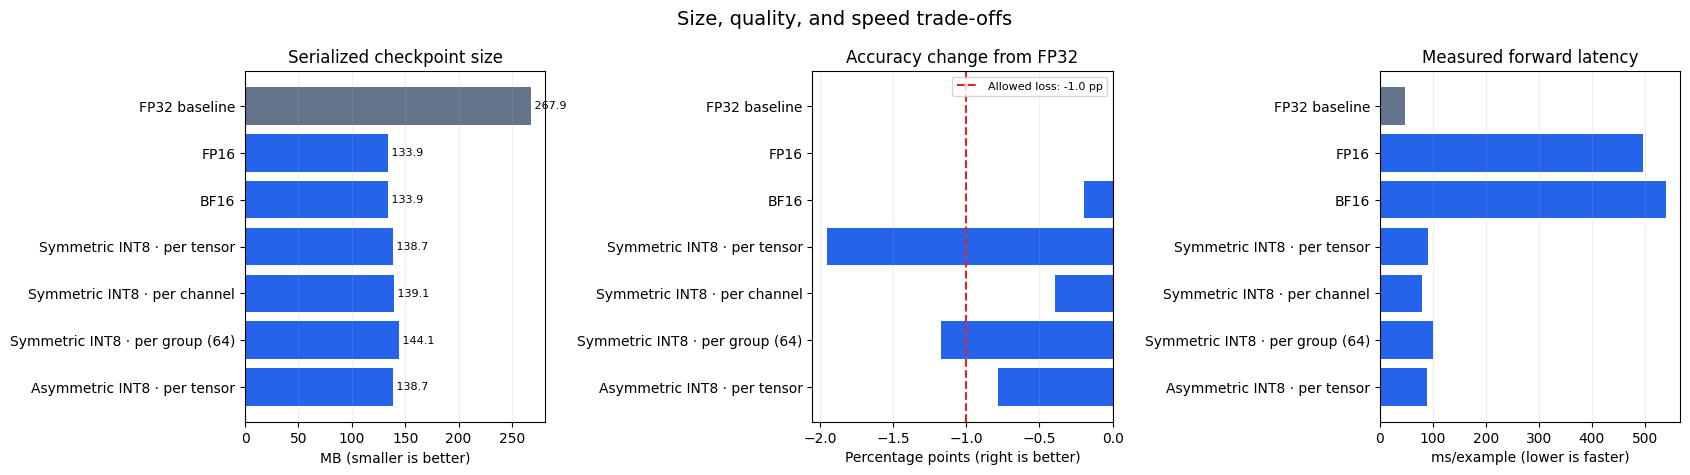

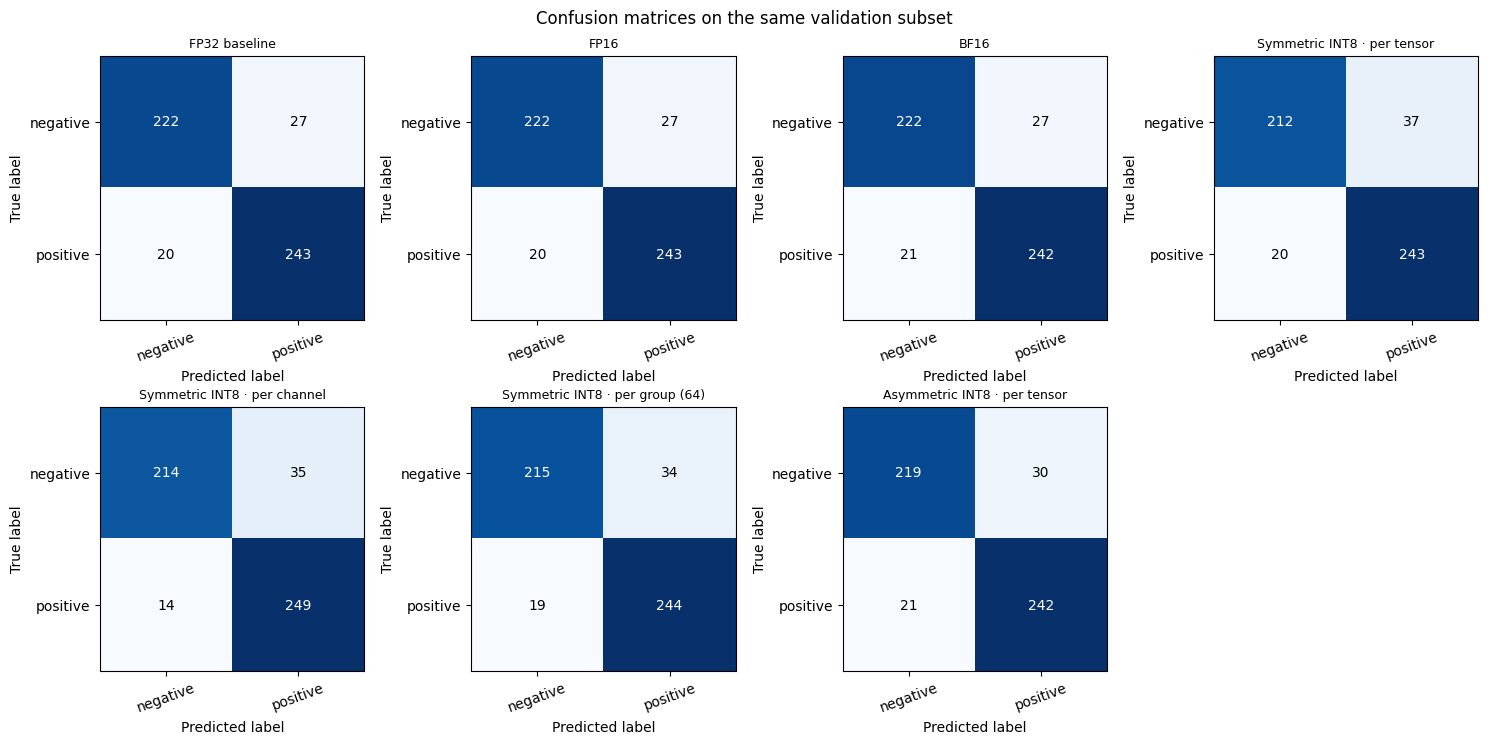

In [25]:
results_table = pd.DataFrame(results)
display(results_table[[
    "configuration", "status", "artifact_MB", "reduction_percent",
    "accuracy_percent", "accuracy_delta_pp", "macro_f1",
    "mean_logit_mae", "latency_ms_per_example", "artifact_path", "error",
]])

completed = results_table[results_table.status == "completed"].copy()
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
colors = ["#64748b" if name == "FP32 baseline" else "#2563eb"
          for name in completed.configuration]

axes[0].barh(completed.configuration, completed.artifact_MB, color=colors)
axes[0].invert_yaxis()
axes[0].set_title("Serialized checkpoint size")
axes[0].set_xlabel("MB (smaller is better)")
for i, value in enumerate(completed.artifact_MB):
    axes[0].text(value, i, f" {value:.1f}", va="center", fontsize=8)

axes[1].barh(completed.configuration, completed.accuracy_delta_pp, color=colors)
axes[1].axvline(-ACCURACY_TOLERANCE_PP, color="#dc2626", linestyle="--",
                label=f"Allowed loss: {-ACCURACY_TOLERANCE_PP:.1f} pp")
axes[1].axvline(0, color="#334155", linewidth=0.8)
axes[1].invert_yaxis()
axes[1].set_title("Accuracy change from FP32")
axes[1].set_xlabel("Percentage points (right is better)")
axes[1].legend(fontsize=8)

axes[2].barh(completed.configuration, completed.latency_ms_per_example, color=colors)
axes[2].invert_yaxis()
axes[2].set_title("Measured forward latency")
axes[2].set_xlabel("ms/example (lower is faster)")
for axis in axes:
    axis.grid(axis="x", alpha=0.2)
fig.suptitle("Size, quality, and speed trade-offs", fontsize=14)
fig.tight_layout()
plt.show()

fig, axes = plt.subplots(2, 4, figsize=(15, 7.5))
for axis, (_, row) in zip(axes.flat, completed.iterrows()):
    matrix = confusion_matrices[row.configuration].numpy()
    axis.imshow(matrix, cmap="Blues")
    axis.set_title(row.configuration, fontsize=9)
    axis.set_xlabel("Predicted label")
    axis.set_ylabel("True label")
    axis.set_xticks([0, 1], ["negative", "positive"], rotation=20)
    axis.set_yticks([0, 1], ["negative", "positive"])
    for y in range(2):
        for x in range(2):
            axis.text(x, y, str(matrix[y, x].item()), ha="center", va="center",
                      color="white" if matrix[y, x] > matrix.max() / 2 else "black")
for axis in axes.flat[len(completed):]:
    axis.axis("off")
fig.suptitle("Confusion matrices on the same validation subset")
fig.tight_layout()
plt.show()


## 7. Select, save, and interpret

In [26]:
candidates = completed[completed.configuration != "FP32 baseline"]
eligible = candidates[candidates.accuracy_delta_pp >= -ACCURACY_TOLERANCE_PP]
if eligible.empty:
    winner = None
    print(f"No reduced-precision scheme met the {ACCURACY_TOLERANCE_PP:.1f} pp accuracy constraint.")
else:
    winner = eligible.sort_values(
        ["artifact_bytes", "mean_logit_mae"], ascending=[True, True]
    ).iloc[0]
    print(f"Selected: {winner.configuration}")
    print(f"Accuracy change: {winner.accuracy_delta_pp:.3f} pp; "
          f"size reduction: {winner.reduction_percent:.2f}%; "
          f"logit MAE: {winner.mean_logit_mae:.5f}")

results_table.to_csv(OUTPUT_DIR / "results.csv", index=False)
summary = {
    "model": MODEL_ID, "dataset": f"{DATASET_ID}/{DATASET_CONFIG}",
    "device": str(DEVICE), "torch_version": torch.__version__, "seed": SEED,
    "evaluation_examples": len(eval_texts), "calibration_examples": len(calibration_texts),
    "batch_size": BATCH_SIZE, "max_length": MAX_LENGTH,
    "accuracy_tolerance_pp": ACCURACY_TOLERANCE_PP,
    "winner": None if winner is None else str(winner.configuration),
    "results": results,
}
(OUTPUT_DIR / "results.json").write_text(json.dumps(summary, indent=2), encoding="utf-8")
print("Saved results.csv, results.json, and successful non-FP32 checkpoints in artifacts/.")


Selected: FP16
Accuracy change: 0.000 pp; size reduction: 49.99%; logit MAE: 0.00125
Saved results.csv, results.json, and successful non-FP32 checkpoints in artifacts/.


## Findings and limitations

- The INT8 implementation is post-training fake quantization written with raw PyTorch. It quantizes all `nn.Linear` weights and inputs; embeddings, layer norms, and other non-linear parameters remain FP32. The per-group scheme stores one symmetric weight scale for each 64-value block in every output row.
- Activation scales use simple training-subset min/max calibration. Outliers can consume quantization range; percentile or token-wise calibration would be a separate experiment.
- FP16/BF16 may be unsupported or slower on some CPUs. The notebook records the local result rather than assuming acceleration.
- INT8 forward calls dequantize and use floating-point kernels. Reported latency is not a claim of native integer speedup.
- Results use a subset of SST-2 validation examples and are hardware-specific. They are a controlled class project experiment, not production benchmarks.
- The INT8 `.pt` files contain custom wrapper state dictionaries, not drop-in Hugging Face checkpoints. FP16/BF16 `.pt` files contain standard architecture state dictionaries with cast parameters.




# Sources
```Refer the doc directory where I referenced and included the books, blogs, and github repos I referred while doing this task.```